# Telco Customer Churn Prediction

The task is to predict if a telecom customer will churn based on their account information\.

Dataset : https://www\.kaggle\.com/datasets/blastchar/telco\-customer\-churn

In [7]:
import pandas as pd 
import numpy as np  
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    cross_validate, RandomizedSearchCV,
    StratifiedKFold, RepeatedStratifiedKFold,
    learning_curve, validation_curve
)
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from imblearn.pipeline import Pipeline as IMBPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from scipy.stats import loguniform, uniform
import itertools
import warnings
warnings.filterwarnings('ignore')

The dataset contains details of persons  who are customers of a telecom service and importantly will reveal whether if they churn or not which is our target\. Data is represented by tabular data and describes each customers personal features\. We load the dataset through read\_csv and with \.shape we learned how many columns and rows that we have\. And with \.head\(10\) we can see 10 rows of our table\.

In [8]:
telco_data = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(f"Dataset shape: {telco_data.shape}")
telco_data.head(10)

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


With \.info we check which columns are numbers and which columns are text\(categories\), this will help us for building the preprocessing pipeline\. Something came up to my realization here, total charges was  a type of object which is weird because it should be float or int\.

In [9]:
telco_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


With \.value\_counts we want to see the distribution of our target values, trying to understand how balanced or imbalanced the classes are\.

In [12]:
print("Target variable distribution:")
print(telco_data['Churn'].value_counts())
print("\nAs percentages:")
print(telco_data['Churn'].value_counts(normalize=True).round(3))

Target variable distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

As percentages:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


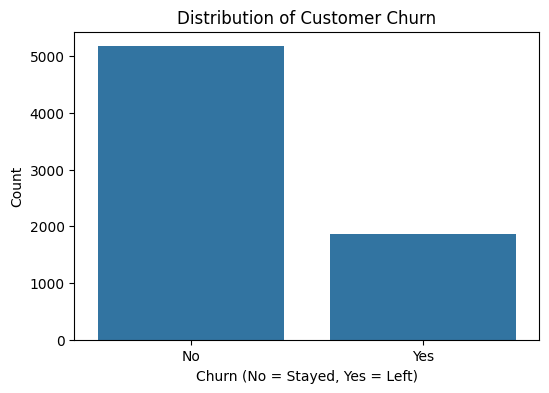

In [15]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=telco_data)
plt.title('Distribution of Customer Churn')
plt.xlabel('Churn (No = Stayed, Yes = Left)')
plt.ylabel('Count')
plt.show()

## Missing Value Analysis

Here with \.isnull\(\)\.sum\(\) we are trying to understand the missing values but there seems none of them\.

In [18]:
print("Missing values per column:")
print(telco_data.isnull().sum())

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


It seems like we didn't have any visible missing data but, TotalCharges being object crossed my mind and I thought there could be a potential non\-numeric value in this column, which came to be true\.

In [21]:
print(f"TotalCharges data type: {telco_data['TotalCharges'].dtype}")
print(f"Rows with empty strings: {(telco_data['TotalCharges'].str.strip() == '').sum()}")

TotalCharges data type: object
Rows with empty strings: 11


Now its time to change TotalCharges to a numeric value I have done that with pd\.to\_numeric\(\) and the solved the problem of NaN values with errors\_'coerce' when it finds something that can't be converted \(like the empty strings that we have\) it will turn them into NaN\. And at the end when we check for missing values again, we can find them out\.

In [24]:
telco_data['TotalCharges'] = pd.to_numeric(telco_data['TotalCharges'], errors='coerce')
print("Missing values after fixing TotalCharges:")
print(telco_data.isnull().sum())

Missing values after fixing TotalCharges:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


Here we have the clear visible representation of the missing values in our dataset which are shown with white lines in the TotalCharges column\.

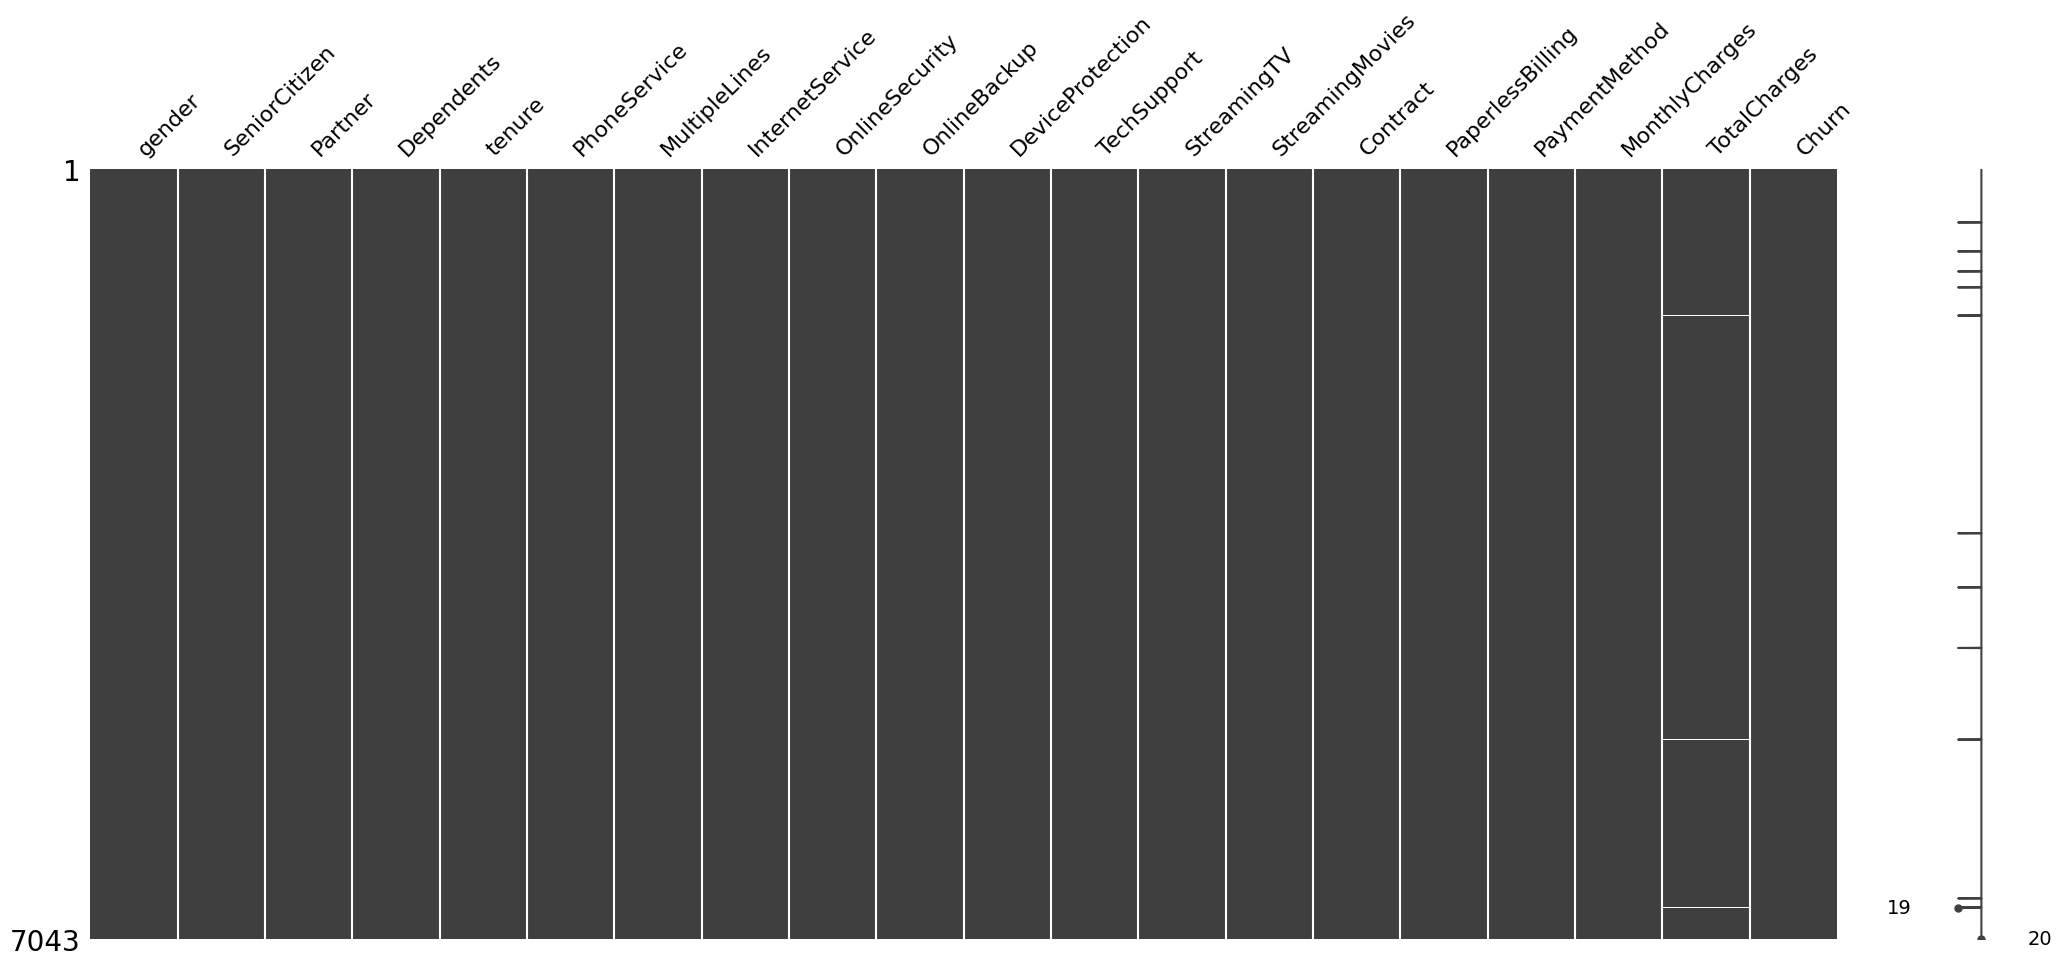

In [27]:
msno.matrix(telco_data.drop(columns=['customerID']))
plt.show()

## Data Preprocessing

From now on we can start preprocessing before feeding our model with data we need to transform it into machine readable and understandable format\.

Here we are separating:

1\) Features \(X\), except customerID because its useless and Churn because we are predicting it, its not a feature\.

2\) Target \(Y\), which is Churn column\. I have changed the type of it because while I was at the calculation of F1 scores process, I got an error since all lines was string\.

In [30]:
X = telco_data.drop(columns=['customerID', 'Churn'])
y = (telco_data['Churn'] == 'Yes').astype(int)

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (7043, 19)
Target shape: (7043,)


We will need to tell the ColumnTransformer which columns get which treatment:

1\) Numerical Columns, these are real numbers they will need SimpleImputer \(for missing values\), and StandardScaler to scale them\.

2\)Ordinal Columns, in Contract column there is a meaningful order where longer contracts mean more commitment\.

3\)Nominal Columns, these are everything else that is text\.

4\) Binary Columns, they are already 0 or 1, no transformation is needed\.

In [33]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

ordinal_cols = ['Contract']

nominal_cols = ['gender', 'Partner', 'Dependents', 'PhoneService',
'MultipleLines', 'InternetService', 'OnlineSecurity','OnlineBackup',
'DeviceProtection', 'TechSupport','StreamingTV', 'StreamingMovies',
'PaperlessBilling','PaymentMethod']

binary_cols = ['SeniorCitizen']

In [36]:
contract_order = ['Month-to-month', 'One year', 'Two year']

Now we are building our preprocessing pipeline using ColumnTransformer, for to apply different transformation to different types of columns which we have described before:

1\) Numerical\_Pipeline : We had missing values in one column as we have seen before so I have used SimpleImputer to fill the missing values with middle value\(strategy='median'\)\. Then StandardScaler to put all the numbers on the same scale\.

2\) Ordinal\_Pipeline : OrdinalEncoder converts contract into 0: Month to Month, 1: One Year, 2: Two Years\. Then with MinMaxScaler\(\) scales its range to 0\-1\.

3\) OneHotEncoder : Its for nominal categories, it creates binary columns\. So basically we are diving to columns for each attributes possible answer\. And notice that InternetServie has three values DSL, Fiber Optic, and No\. OneHotEncoder creates a column for each one, but notice if DSL=0 and Fiber Optic=0 it must be No which means we don't need the last column, we can figure it out from the other two\. So I have used drop='first'\. And it works for any other Nominal columns\.

In [39]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ordinal_pipeline = Pipeline([
    ('encoder', OrdinalEncoder(categories=[contract_order])),
    ('scaler', MinMaxScaler())
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_cols),
    ('ord', ordinal_pipeline, ordinal_cols),
    ('nom', OneHotEncoder(drop='first', handle_unknown='ignore'), nominal_cols),
    ('bin', 'passthrough', binary_cols)
])

Here I wanted to put a demonstration on what OneHotEncoder and drop='first' does, The visualization of tables aren't like we have mentioned\(After OneHotEncoder there will be 3 columns for  FiberOptic\-DSL\-No and with drop='first' we will remove the unnecessary one and we will get a table with 2 columns\) that didn't happen we only have 2 and 1 columns because we are only sampling on 10 rows,  which means they don't have No value between them\.

In [42]:
from sklearn.preprocessing import OneHotEncoder

# Small sample to visualize
sample = telco_data[['InternetService']].head(10)
print("BEFORE encoding:")
print(sample)
print()

ohe_full = OneHotEncoder(sparse_output=False)
encoded_full = ohe_full.fit_transform(sample)
print("AFTER encoding (all categories):")
print(pd.DataFrame(encoded_full, columns=ohe_full.get_feature_names_out()))
print()

ohe_drop = OneHotEncoder(sparse_output=False, drop='first')
encoded_drop = ohe_drop.fit_transform(sample)
print("AFTER encoding (drop='first' which removes redundant column):")
print(pd.DataFrame(encoded_drop, columns=ohe_drop.get_feature_names_out()))

BEFORE encoding:
  InternetService
0             DSL
1             DSL
2             DSL
3             DSL
4     Fiber optic
5     Fiber optic
6     Fiber optic
7             DSL
8     Fiber optic
9             DSL

AFTER encoding (all categories):
   InternetService_DSL  InternetService_Fiber optic
0                  1.0                          0.0
1                  1.0                          0.0
2                  1.0                          0.0
3                  1.0                          0.0
4                  0.0                          1.0
5                  0.0                          1.0
6                  0.0                          1.0
7                  1.0                          0.0
8                  0.0                          1.0
9                  1.0                          0.0

AFTER encoding (drop='first' which removes redundant column):
   InternetService_Fiber optic
0                          0.0
1                          0.0
2                      

## Splitting Training and Test Set

We split the data with a distribution of %80 training and %20 test sets\. We will discard the test set till the end of the workflow \(until model selection process\)\. And we are using stratify=y for preserving the class distribution\.

In [45]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,stratify=y,random_state=42,shuffle=True)

And here is a visual presentation where we can understand the distribution of training\-set split and distribution of our target\.

In [48]:
print(f"Training: {X_train.shape[0]} samples")
print(f"Test: {X_test.shape[0]} samples")
print(f"\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))
print(f"\nTest target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training: 5634 samples
Test: 1409 samples

Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Test target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


## Model Selection

Until now we have dealt with preprocessing the data and split it into test and train pairs\. Now we have to find the best model\. From now on we are going to try different combinations of sampling techniques, dimensionality reduction and classifiers\. These combinations are going to be our candidate models and via Nested CV process we will select the best models\.

We put all of this stages into a single pipeline which has 4 stages:

1\)Preprocessing which is the ColumnTransfer we have build before, after the processes which will happen in this step our data will be ready to be machine readable and will be numeric\.

 2\) Sampling will deal with class balancing since our targets distribution is 73\.5% to 26\.5%, most classifiers would just predict the choice which is the one with 73\.5% and they will get 73\.5% accuracy, sampler fixes that by changing the distribution\.

3\) Dimensionality Reduction, especially after OneHotEncoding we can have a lot of features which some of them are unnecessary, we will compress the information with Dimensionality Reduction\.

4\) Classification, this is the actual model that learns patterns and make predictions\.

 The data will flow through each stage in order\.

In [51]:
model_pipeline = IMBPipeline([
    ('trans', preprocessor),
    ('sampler', SMOTE()),
    ('dim_reduction', PCA(n_components=0.8)),
    ('classifier', Perceptron())
])

Now we are doing a sanity check to make sure nothing crashes\.

In [54]:
model_pipeline.fit(X_train, y_train)

Pipeline(steps=[('trans',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('ord',
                                                  Pipeline(steps=[('encoder',
                                                                   OrdinalEncoder(categories=[['Month-to-month',
                                                                                               'One '
                                                                                               'year',
                                                                                               'Two '
                                                                                               'year']])),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['Contract']),
                                                 ('...
                                                                handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('bin', 'passthrough',
                                                  ['SeniorCitizen'])])),
                ('sampler', SMOTE()), ('dim_reduction', PCA(n_components=0.8)),
                ('classifier', Perceptron())])

In [55]:
model_pipeline.predict(X_test)

array([0, 1, 0, ..., 0, 0, 0])

This step we will define the options we want to try for each stage of the pipeline\.

For sampler we will have three options:

1\) None, which will just bypass the balancing process\.

2\) SMOTE, will create new minority samples by mixing the existing ones\.

3\) RandomOverSampler, will duplicate existing minority samples randomly\.

And we also will try different sampling strategy values like 0\.9 and 0\.7 which makes minority to become %90 and %70 of majority because we want to see which ratio gives the best results\.

In [58]:
sampler_configs = [
    {
        'sampler': [None]
    },
    {
        'sampler': [SMOTE()],
        'sampler__sampling_strategy': ['minority', 0.9, 0.7]
    },
    {
        'sampler': [RandomOverSampler()],
        'sampler__sampling_strategy': ['minority', 0.9, 0.7]
    }
]

For dimensionality reduction we have two options:

1\) None, keeps all of the features\.

2\) PCA, will compress our features while keeping a percantage of information that we have defined\. 

In [61]:
dim_reduction_configs = [
    {
        'dim_reduction': [None]
    },
    {
        'dim_reduction': [PCA()],
        'dim_reduction__n_components': [0.7, 0.9]
    }
]

For classifier we have four options:

1\) LogisticRegression, which basically draws a line that separates target values\.

2\) KNeighborsClassifier, looks at the K nearest data points \(K is predefined such as 3,5,7,9\) and predicts based on their labels\.

3\) RandomForestClassifier, builds multiple decision trees\. We will try different numbers of trees which are 10,50,100\.

4\) Perceptron, draws a straight line to separate classes\.

In [104]:
classifier_configs = [
    {
        'classifier': [LogisticRegression(solver='saga', max_iter=5000)],
        'classifier__C': loguniform(0.001, 100),
        'classifier__penalty': ['l1', 'l2'],
        'classifier__class_weight': [None, 'balanced']
    },
    {
        'classifier': [KNeighborsClassifier()],
        'classifier__n_neighbors': [3, 5, 7, 9]
    },
    {
        'classifier': [RandomForestClassifier()],
        'classifier__n_estimators': [10, 50, 100]
    },
    {
        'classifier': [Perceptron()],
        'classifier__eta0': loguniform(0.001, 100),
        'classifier__max_iter': [5, 10, 50, 100],
        'classifier__class_weight': [None, 'balanced']
    }
]

Here is the cartesian product of every possible combination\. Since we have 3 sampler, 2 dimensionality reduction and 4 classifier options we have to get 3x2x4 = 24 base configurations\.

In [107]:
all_configs = [dict(itertools.chain(*(e.items() for e in configuration)))
               for configuration in itertools.product(sampler_configs, dim_reduction_configs, classifier_configs)]

print(f"Total number of configurations: {len(all_configs)}")

Total number of configurations: 24


Now we create our RandomizedSearchCV which will try 50 random combinations from our 24 configurations and use F1 scoring because accuracy can be misleading with imbalanced data\.

In [110]:
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=model_pipeline,
    param_distributions=all_configs,
    n_iter=50,
    scoring='f1',
    cv=inner_cv,
    random_state=42,
    n_jobs=-1,
    error_score=0.0
)

Here is our cross\_validate function uses F1 score metrics, 5\-fold cross validation\. Each outer fold runs an independent search\. 

In [113]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

nested_scores = cross_validate(
    search,
    X_train, y_train,
    cv=outer_cv,
    scoring='f1',
    return_estimator=True,
    n_jobs=-1
)

print(f"Nested CV F1 scores: {nested_scores['test_score']}")
print(f"Mean F1: {nested_scores['test_score'].mean():.4f} (+/- {nested_scores['test_score'].std():.4f})")

/root/venv/lib/python3.11/site-packages/sklearn/linear_model/_stochastic_gradient.py:713: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/root/venv/lib/python3.11/site-packages/sklearn/linear_model/_stochastic_gradient.py:713: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/root/venv/lib/python3.11/site-packages/sklearn/linear_model/_stochastic_gradient.py:713: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/root/venv/lib/python3.11/site-packages/sklearn/linear_model/_stochastic_gradient.py:713: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/root/venv/lib/python3.11/site-packages/sklearn/linear_model/_stochastic

Each outer fold produced a winner, now we can look at all 5 winners\. From the view we basically can see that LogisticRegression won in every fold\. It shows that LogisticRegression is the best choice for this dataset\.

In [116]:
for i, estimator in enumerate(nested_scores['estimator']):
    print(f"Fold {i+1} best config:")
    best = estimator.best_params_
    print(f"  Classifier: {best.get('classifier', 'N/A')}")
    print(f"  Sampler: {best.get('sampler', 'N/A')}")
    print(f"  Dim reduction: {best.get('dim_reduction', 'N/A')}")
    print(f"  F1 (inner CV): {estimator.best_score_:.4f}")
    print()

Fold 1 best config:
  Classifier: LogisticRegression(max_iter=5000, solver='saga')
  Sampler: RandomOverSampler()
  Dim reduction: None
  F1 (inner CV): 0.6317

Fold 2 best config:
  Classifier: LogisticRegression(max_iter=5000, solver='saga')
  Sampler: SMOTE()
  Dim reduction: None
  F1 (inner CV): 0.6437

Fold 3 best config:
  Classifier: LogisticRegression(max_iter=5000, solver='saga')
  Sampler: RandomOverSampler()
  Dim reduction: None
  F1 (inner CV): 0.6379

Fold 4 best config:
  Classifier: LogisticRegression(max_iter=5000, solver='saga')
  Sampler: SMOTE()
  Dim reduction: None
  F1 (inner CV): 0.6294

Fold 5 best config:
  Classifier: LogisticRegression(max_iter=5000, solver='saga')
  Sampler: RandomOverSampler()
  Dim reduction: PCA()
  F1 (inner CV): 0.6288



Now we retrain each of the 5 candidates on the full training set and test them on test set\.\. This lets us directly to compare all 5 candidates on the same test data, by this process we can choose our champion\. \(best score in test F1\)\.

In [119]:
for i, estimator in enumerate(nested_scores['estimator']):
    estimator.best_estimator_.fit(X_train, y_train)
    pred_train = estimator.best_estimator_.predict(X_train)
    pred_test = estimator.best_estimator_.predict(X_test)
    f1_train = f1_score(y_train, pred_train)
    f1_test = f1_score(y_test, pred_test)
    print(f"Candidate {i+1}: Train F1: {f1_train:.4f}, Test F1: {f1_test:.4f}")

Candidate 1: Train F1: 0.6352, Test F1: 0.6182
Candidate 2: Train F1: 0.6385, Test F1: 0.6117
Candidate 3: Train F1: 0.6342, Test F1: 0.6127
Candidate 4: Train F1: 0.6333, Test F1: 0.6136
Candidate 5: Train F1: 0.6332, Test F1: 0.6123


## Refinement

We have already identified our wining combination\. Now we have to zoom in into that combination and search for its hyper parameters more detailed\. Then we define another RandomizedSearchCV  object for the model pipeline\. 

In [122]:
refined_pipeline = IMBPipeline([
    ('trans', preprocessor),
    ('sampler', RandomOverSampler()),
    ('classifier', LogisticRegression(solver='saga', max_iter=5000))
])

refined_params = {
    'sampler__sampling_strategy': ['minority', 0.9, 0.8, 0.7],
    'classifier__C': loguniform(0.001, 100),
    'classifier__penalty': ['l1', 'l2'],
    'classifier__class_weight': [None, 'balanced']
}

refined_search = RandomizedSearchCV(
    estimator=refined_pipeline,
    param_distributions=refined_params,
    n_iter=100,
    scoring='f1',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1
)

refined_search.fit(X_train, y_train)

print(f"Best F1 (CV): {refined_search.best_score_:.4f}")
print(f"Best params: {refined_search.best_params_}")

Best F1 (CV): 0.6392
Best params: {'classifier__C': 2.211160656586085, 'classifier__class_weight': None, 'classifier__penalty': 'l1', 'sampler__sampling_strategy': 0.7}


Test set was locked away since the beginning, now we use it to get the final score\. Our final F1 Score is 0\.62 since its close to the CV estimation of 0\.64, it confirms the model generalizes well and confirms that the model is not overfitting\.

In [128]:
from sklearn.metrics import classification_report

# The best model is already fitted on X_train from refined_search
y_pred = refined_search.predict(X_test)

print("Final Test Set Results:")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print()
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

Final Test Set Results:
F1 Score: 0.6163

Confusion Matrix:
[[805 230]
 [105 269]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.88      0.78      0.83      1035
       Churn       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



Now we can visualize our learning curve\. It shows us how our model's performance changes as we give it more training data\. In the graph the x\-axis represents the training set size and y\-axis represents the F1 scores\. We plot two lines:

1\) Training F1\(Blue Line\), shows how well the model does on data is has already seen\.

2\) Validation F1\(Orange Line\), shows how well the model does on the data that it hasn't seen\.

We can see that as the training size increases the gap between lines get smaller, this shows us that our model is not overfitting\.

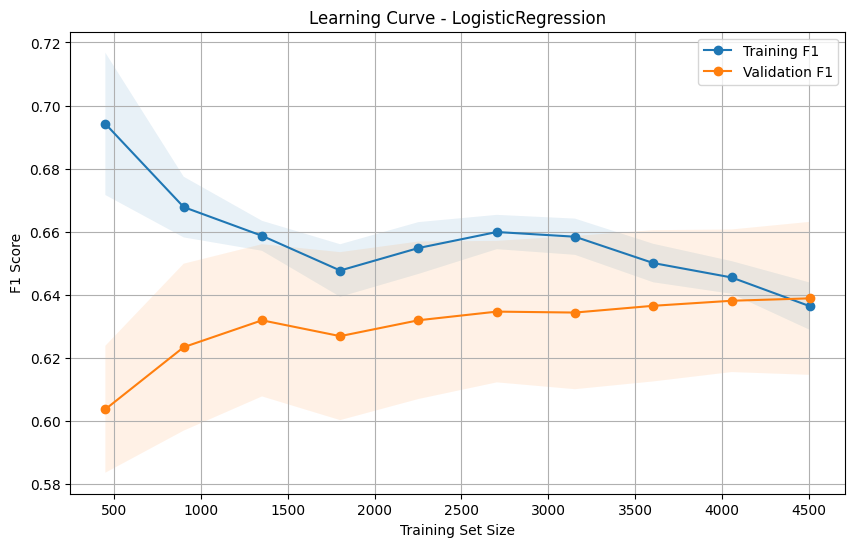

In [131]:
train_sizes, train_scores, val_scores = learning_curve(
    refined_search.best_estimator_,
    X_train, y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Training F1')
plt.plot(train_sizes, val_scores.mean(axis=1), 'o-', label='Validation F1')
plt.fill_between(train_sizes,
                 train_scores.mean(axis=1) - train_scores.std(axis=1),
                 train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.1)
plt.fill_between(train_sizes,
                 val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.1)
plt.xlabel('Training Set Size')
plt.ylabel('F1 Score')
plt.title('Learning Curve - LogisticRegression')
plt.legend()
plt.grid(True)
plt.show()

Now we are looking at our validation curve which shows how hyper parameter C affects performance\. The visualization shows that for very small C values the model underfits because the regularization is too strong and model can't learn anything useful\. But for higher C values\(approximately above 0\.3\), both training and validation scores flatten around 0\.64 with almost no gap between them\. This tells us our model has low variance and is not overfitting even with weak regularization\.

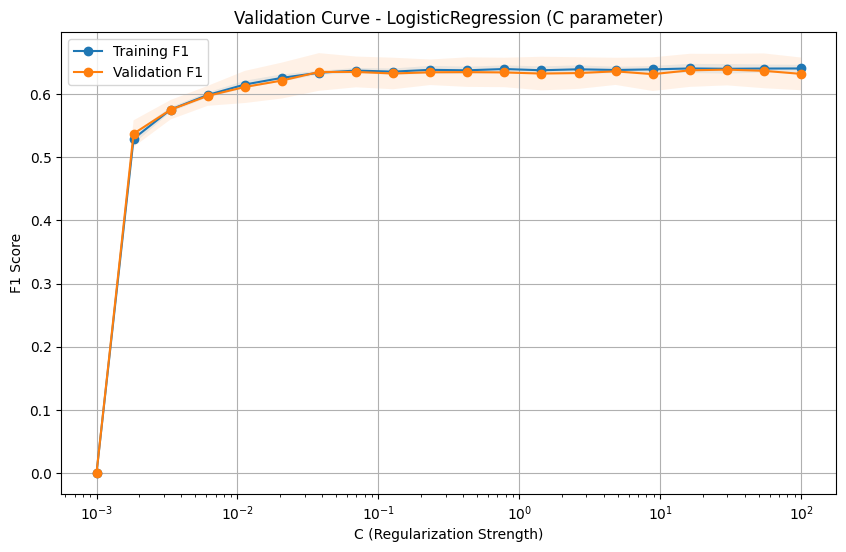

In [134]:
C_range = np.logspace(-3, 2, 20)

train_scores_vc, val_scores_vc = validation_curve(
    refined_search.best_estimator_,
    X_train, y_train,
    param_name='classifier__C',
    param_range=C_range,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1',
    n_jobs=-1
)

plt.figure(figsize=(10, 6))
plt.semilogx(C_range, train_scores_vc.mean(axis=1), 'o-', label='Training F1')
plt.semilogx(C_range, val_scores_vc.mean(axis=1), 'o-', label='Validation F1')
plt.fill_between(C_range,
                 train_scores_vc.mean(axis=1) - train_scores_vc.std(axis=1),
                 train_scores_vc.mean(axis=1) + train_scores_vc.std(axis=1), alpha=0.1)
plt.fill_between(C_range,
                 val_scores_vc.mean(axis=1) - val_scores_vc.std(axis=1),
                 val_scores_vc.mean(axis=1) + val_scores_vc.std(axis=1), alpha=0.1)
plt.xlabel('C (Regularization Strength)')
plt.ylabel('F1 Score')
plt.title('Validation Curve - LogisticRegression (C parameter)')
plt.legend()
plt.grid(True)
plt.show()

## Conclusion

Best model for predicting customers churn turned out to be Logistic Regression with L1 penalty and RandomOverSampler\. The model catches 73% of the churners which is useful\.